# Rubies MFB — Loan Prediction Model Training

**Purpose:** document the initial capstone ML workflow from loading the public Kaggle Loan Prediction dataset through EDA, feature engineering, preprocessing, train/validation/test evaluation, and versioned artifact creation.

> **Scope and limitation:** this is a demonstration classifier trained on historical Kaggle `Loan_Status` labels. It is not a Rubies MFB lending policy, not a production-ready credit-risk model, and must not autonomously approve/reject or disburse loans.

**Reproducibility:** run from the repository root. Place the labelled Kaggle training CSV at `data/model/training/loan_prediction.csv` (or keep its original Kaggle filename in that folder). The separate Kaggle test CSV has no labels and is not used for evaluation here; we create our own stratified train/validation/test splits from the labelled training CSV.

## 1. Imports and reproducibility

If needed in the project environment, install the notebook dependencies with `uv add --dev jupyter pandas matplotlib joblib scikit-learn` (or use the repository's existing dependency conventions).

In [16]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "Loan_Status"
REPO_ROOT = Path.cwd()

if REPO_ROOT.name.lower() == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

TRAINING_DIR = REPO_ROOT / "data" / "model" / "training"
TRAINING_DIR = REPO_ROOT / "data" / "model" / "training"

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Working directory:", REPO_ROOT.resolve())

Python: 3.12.15
pandas: 3.1.0
scikit-learn: 1.9.1
Working directory: C:\Users\ADMIN\Downloads\rubies-mfb-agent


## 2. Load the labelled dataset

In [5]:
candidate_paths = [
    TRAINING_DIR / "loan_prediction.csv",
    TRAINING_DIR / "train_u6lujuX_CVtuZ9i.csv",
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Training CSV not found. Copy the labelled Kaggle training file to "
        f"{TRAINING_DIR / 'loan_prediction.csv'} and rerun this cell."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print("Shape:", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Loaded: c:\Users\ADMIN\Downloads\rubies-mfb-agent\notebooks\data\model\training\train_u6lujuX_CVtuZ9i.csv
Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
350,LP002139,Male,Yes,0,Graduate,No,9083,0.0,228.0,360.0,1.0,Semiurban,Y
377,LP002223,Male,Yes,0,Graduate,No,4310,0.0,130.0,360.0,NaN,Semiurban,Y
163,LP001570,Male,Yes,2,Graduate,No,4167,1447.0,158.0,360.0,1.0,Rural,Y
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
132,LP001478,Male,No,0,Graduate,No,2718,0.0,70.0,360.0,1.0,Semiurban,Y


## 3. Basic EDA and data quality

Column names and types


,dtype,missing,missing_pct,unique_values
Loan_ID,str,0,0.0,614
Gender,str,13,2.1,3
Married,str,3,0.5,3
Dependents,str,15,2.4,5
Education,str,0,0.0,2
Self_Employed,str,32,5.2,3
ApplicantIncome,int64,0,0.0,505
CoapplicantIncome,float64,0,0.0,287
LoanAmount,float64,22,3.6,204
Loan_Amount_Term,float64,14,2.3,11


Numeric summary


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


Categorical summary


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17280\2423023651.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=["object"]).T)


,count,unique,top,freq
Loan_ID,614,614,LP001002,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


Target counts


,count
Loan_Status,
Y,422
N,192


Target proportions


,proportion
Loan_Status,
Y,0.687
N,0.313


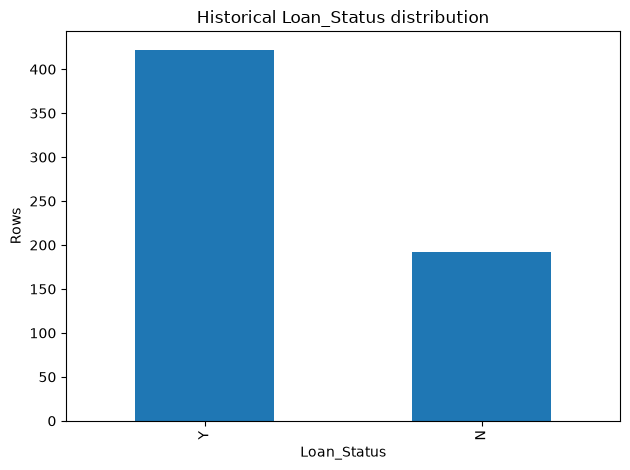

In [6]:
print("Column names and types")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(1), "unique_values": df.nunique(dropna=False)}))
print("Numeric summary")
display(df.describe(include=[np.number]).T)
print("Categorical summary")
display(df.describe(include=["object"]).T)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r} was not found.")
print("Target counts")
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count"))
print("Target proportions")
display(df[TARGET].value_counts(normalize=True, dropna=False).round(3).rename("proportion").to_frame())

ax = df[TARGET].value_counts(dropna=False).plot(kind="bar", title="Historical Loan_Status distribution")
ax.set_xlabel("Loan_Status")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()

### Initial observations

- `Loan_ID` is an identifier and is excluded from model features.
- The labelled file has 614 rows; the target is historically imbalanced (`Y`/`N`). Metrics beyond accuracy are therefore important.
- Missing values are handled inside the preprocessing pipeline so the same transformations are applied at training and inference time.
- The separate Kaggle `test` CSV does not contain `Loan_Status`, so it cannot provide labelled evaluation metrics. We create our own held-out splits from the labelled training file.

## 4. Validate target and prepare features

In [7]:
df = df.dropna(subset=[TARGET]).copy()
# Keep only the two known labels; fail loudly if the source changes unexpectedly.
observed_labels = set(df[TARGET].astype(str).unique())
if not observed_labels.issubset({"Y", "N"}) or not observed_labels:
    raise ValueError(f"Unexpected target labels: {observed_labels}")

# Encode the target as 1 = historically approved (Y), 0 = historically not approved (N).
y = df[TARGET].map({"Y": 1, "N": 0}).astype(int)
X = df.drop(columns=[TARGET, "Loan_ID"], errors="ignore").copy()

# Normalize the Dependents value '3+' into a consistent category; keep it categorical.
if "Dependents" in X.columns:
    X["Dependents"] = X["Dependents"].map(lambda value: np.nan if pd.isna(value) else str(value))

print("Features before engineering:", X.columns.tolist())
print("X shape:", X.shape, "y shape:", y.shape)
print("Label mapping: Y -> 1, N -> 0")

Features before engineering: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
X shape: (614, 11) y shape: (614,)
Label mapping: Y -> 1, N -> 0


## 5. Feature engineering

In [8]:
# Row-wise derived features. These are illustrative signals, not lending-policy rules.
# Keep original source fields as well; all transformations are deterministic per row.
if {"ApplicantIncome", "CoapplicantIncome"}.issubset(X.columns):
    X["TotalIncome"] = X["ApplicantIncome"].fillna(0) + X["CoapplicantIncome"].fillna(0)

if {"ApplicantIncome", "CoapplicantIncome", "LoanAmount"}.issubset(X.columns):
    total_income = X["ApplicantIncome"].fillna(0) + X["CoapplicantIncome"].fillna(0)
    loan_amount = pd.to_numeric(X["LoanAmount"], errors="coerce")
    # Avoid divide-by-zero; missing/invalid ratios are imputed by the numeric pipeline.
    X["IncomeToLoanAmountRatio"] = np.where(loan_amount > 0, total_income / loan_amount, np.nan)

# Explicitly ensure the source's categorical-looking Dependents column remains categorical.
for col in ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]:
    if col in X.columns:
        X[col] = X[col].astype("object")

print("Features after engineering:", X.columns.tolist())
display(X.head())

Features after engineering: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'TotalIncome', 'IncomeToLoanAmountRatio']


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,TotalIncome,IncomeToLoanAmountRatio
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,5849.0,NaN
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0,47.585938
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0,45.454545
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0,41.175000
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0,42.553191


## 6. Stratified train / validation / test split

In [9]:
# 70% train, 15% validation, 15% test (approximately; stratified by target).
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positive_rate_Y": [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary.round(3))
print("No validation/test rows are used to fit preprocessing or model parameters.")

,split,rows,positive_rate_Y
0,train,429,0.688
1,validation,92,0.685
2,test,93,0.688


No validation/test rows are used to fit preprocessing or model parameters.


## 7. Preprocessing pipeline

In [10]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'TotalIncome', 'IncomeToLoanAmountRatio']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']


## 8. Train candidate models and select on validation set

In [11]:
# Small, explicit hyperparameter sweep to keep the workflow fast and reproducible.
validation_results = []
candidate_models = {}
for c_value in [0.1, 1.0, 10.0]:
    candidate = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=c_value, max_iter=2000, class_weight=None, random_state=RANDOM_STATE)),
    ])
    candidate.fit(X_train, y_train)
    val_pred = candidate.predict(X_val)
    val_prob = candidate.predict_proba(X_val)[:, 1]
    row = {
        "C": c_value,
        "accuracy": accuracy_score(y_val, val_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, val_pred),
        "precision_Y": precision_score(y_val, val_pred, zero_division=0),
        "recall_Y": recall_score(y_val, val_pred, zero_division=0),
        "f1_Y": f1_score(y_val, val_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, val_prob) if y_val.nunique() == 2 else np.nan,
    }
    validation_results.append(row)
    candidate_models[c_value] = candidate

validation_metrics = pd.DataFrame(validation_results).sort_values(
    ["f1_Y", "roc_auc", "balanced_accuracy"], ascending=False
).reset_index(drop=True)
display(validation_metrics.round(3))
best_c = float(validation_metrics.loc[0, "C"])
print("Selected C from validation results:", best_c)
print("Selection criterion: F1 for historically approved class (Y), with ROC-AUC and balanced accuracy as tie-breakers.")

,C,accuracy,balanced_accuracy,precision_Y,recall_Y,f1_Y,roc_auc
0,0.1,0.837,0.741,0.808,1.0,0.894,0.810
1,1.0,0.837,0.741,0.808,1.0,0.894,0.806
2,10.0,0.837,0.741,0.808,1.0,0.894,0.804


Selected C from validation results: 0.1
Selection criterion: F1 for historically approved class (Y), with ROC-AUC and balanced accuracy as tie-breakers.


## 9. Refit on train + validation, then evaluate once on held-out test

,test_value
accuracy,0.860
balanced_accuracy,0.795
precision_Y,0.849
recall_Y,0.969
f1_Y,0.905
roc_auc,0.841


                            precision    recall  f1-score   support

N: historical not approved       0.90      0.62      0.73        29
    Y: historical approved       0.85      0.97      0.91        64

                  accuracy                           0.86        93
                 macro avg       0.87      0.79      0.82        93
              weighted avg       0.87      0.86      0.85        93



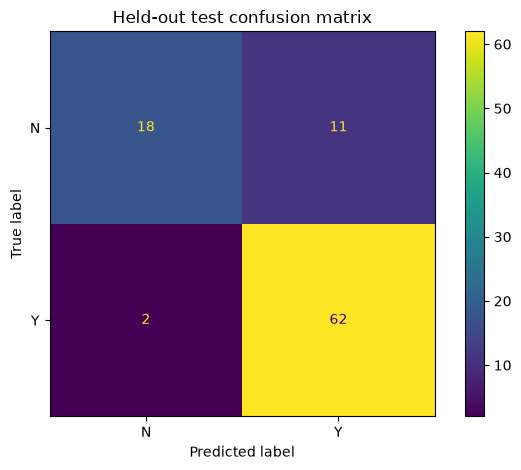

In [12]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=best_c, max_iter=2000, class_weight=None, random_state=RANDOM_STATE)),
])
final_model.fit(X_trainval, y_trainval)

test_pred = final_model.predict(X_test)
test_prob = final_model.predict_proba(X_test)[:, 1]
test_metrics = {
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, test_pred)),
    "precision_Y": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall_Y": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1_Y": float(f1_score(y_test, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, test_prob)) if y_test.nunique() == 2 else None,
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "test_value"}).round(3))
print(classification_report(y_test, test_pred, labels=[0, 1], target_names=["N: historical not approved", "Y: historical approved"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1], display_labels=["N", "Y"])
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

### Evaluation interpretation

Review precision, recall, F1, balanced accuracy, ROC-AUC and the confusion matrix together. This dataset is small, and metrics can vary materially with the split. The model's positive class means **historically approved in the Kaggle data**, not “eligible under Rubies MFB policy.” Do not describe these results as evidence of real-world lending suitability.

## 10. Inspect learned feature names and coefficients

In [13]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
classifier = final_model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = pd.DataFrame({"feature": feature_names, "coefficient": classifier.coef_[0]})
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
display(coefficients.sort_values("absolute_coefficient", ascending=False).head(15).drop(columns="absolute_coefficient"))
print("Coefficients describe this fitted model; they are not causal explanations or lending policy.")

,feature,coefficient
18,categorical__Credit_History_0.0,-1.141977
19,categorical__Credit_History_1.0,1.141884
21,categorical__Property_Area_Semiurban,0.348722
20,categorical__Property_Area_Rural,-0.246815
11,categorical__Dependents_1,-0.236832
12,categorical__Dependents_2,0.227120
8,categorical__Married_No,-0.196237
9,categorical__Married_Yes,0.196144
15,categorical__Education_Not Graduate,-0.191317
14,categorical__Education_Graduate,0.191224


Coefficients describe this fitted model; they are not causal explanations or lending policy.


## 11. Save the versioned model artifact and manifest (ADR-004)

In [14]:
# Fingerprint the exact labelled CSV used for this run.
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

MODEL_VERSION = "loan-logreg-v1"
ARTIFACT_ROOT = REPO_ROOT / "artifacts" / "loan_model"
VERSION_DIR = ARTIFACT_ROOT / "versions" / MODEL_VERSION
MANIFEST_DIR = ARTIFACT_ROOT / "manifests"
VERSION_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

model_path = VERSION_DIR / "model.joblib"
joblib.dump(final_model, model_path)

manifest = {
    "model_version": MODEL_VERSION,
    "artifact_location": model_path.relative_to(REPO_ROOT).as_posix(),
    "artifact_format": "joblib",
    "model_type": "scikit-learn Pipeline: preprocessing + LogisticRegression",
    "target": TARGET,
    "target_mapping": {"N": 0, "Y": 1},
    "target_interpretation": "historical Kaggle Loan_Status only; not Rubies MFB policy eligibility",
    "training_data_path": DATA_PATH.relative_to(REPO_ROOT).as_posix(),
    "training_data_sha256": sha256_file(DATA_PATH),
    "training_data_rows": int(len(df)),
    "feature_schema_version": "loan-applicant-features-v1",
    "input_features": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "engineered_features": [c for c in ["TotalIncome", "IncomeToLoanAmountRatio"] if c in X.columns],
    "split": {"train_rows": int(len(X_train)), "validation_rows": int(len(X_val)), "test_rows": int(len(X_test)), "random_state": RANDOM_STATE},
    "training_config": {"algorithm": "LogisticRegression", "selected_C": best_c, "max_iter": 2000, "class_weight": None, "selection_metric": "validation F1 for class Y"},
    "evaluation_results": test_metrics,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "intended_use": "capstone demonstration and pipeline integration only",
    "limitations": [
        "Small public dataset with historical labels from a different lending context",
        "Not validated for Rubies MFB lending decisions",
        "Predictions must not directly approve, reject, or disburse loans",
        "Feature availability, units, provenance, fairness, and policy alignment require review before any real-world use",
    ],
}
manifest_path = MANIFEST_DIR / f"{MODEL_VERSION}.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved model:", model_path.resolve())
print("Saved manifest:", manifest_path.resolve())
display(pd.DataFrame([{"model": str(model_path), "manifest": str(manifest_path), "version": MODEL_VERSION}]))

Saved model: C:\Users\ADMIN\Downloads\rubies-mfb-agent\notebooks\artifacts\loan_model\versions\loan-logreg-v1\model.joblib
Saved manifest: C:\Users\ADMIN\Downloads\rubies-mfb-agent\notebooks\artifacts\loan_model\manifests\loan-logreg-v1.json


,model,manifest,version
0,c:\Users\ADMIN\Downloads\rubies-mfb-agent\note...,c:\Users\ADMIN\Downloads\rubies-mfb-agent\note...,loan-logreg-v1


## 12. Smoke-test saved artifact with one held-out example

In [15]:
loaded_model = joblib.load(model_path)
example = X_test.iloc[[0]].copy()
probability_y = float(loaded_model.predict_proba(example)[0, 1])
predicted_label = "Y" if int(loaded_model.predict(example)[0]) == 1 else "N"
print({
    "model_version": MODEL_VERSION,
    "predicted_historical_label": predicted_label,
    "probability_historical_Y": round(probability_y, 4),
    "note": "Demonstration prediction only; not a Rubies MFB lending decision.",
})

{'model_version': 'loan-logreg-v1', 'predicted_historical_label': 'Y', 'probability_historical_Y': 0.6743, 'note': 'Demonstration prediction only; not a Rubies MFB lending decision.'}


## 13. Handoff notes

- Model artifact: `artifacts/loan_model/versions/loan-logreg-v1/model.joblib`
- Manifest: `artifacts/loan_model/manifests/loan-logreg-v1.json`
- The artifact contains preprocessing and the classifier together, so inference uses the same imputing, scaling and encoding steps.
- Keep this version immutable after review; any data, feature, or training-configuration change should produce a new version and manifest.
- Next integration step: implement a typed inference interface in `apps/loan_model`, validate required input fields, and connect it to the agent/MCP flow. Do not map absent customer fields to fabricated values.
- `joblib` artifacts should only be loaded from trusted, controlled locations because loading serialized Python objects can execute code.